# Green window scheduling

## Setup

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

import campaign_analysis as ca

plt.rcParams.update({"font.family": "serif", "font.size": 9, "figure.dpi": 110,
                     "axes.grid": True, "axes.axisbelow": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

REPO = Path.cwd().parent
OUT_DIR = REPO / "experiments" / "out"
CAMPAIGN_PATH = REPO / "experiments" / "experiments.toml"
INTENSITIES_DIR = REPO / "intensities"
WINDOWS_PATH = INTENSITIES_DIR / "windows.csv"
CEILING_PATH = REPO / "analysis" / "shift_ceiling_results.csv.gz"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

## Campaign

In [2]:
campaign, windows = ca.load_campaign(CAMPAIGN_PATH, WINDOWS_PATH)
print(f"{len(campaign)} experiments, {len(windows)} windows")

504 experiments, 36 windows


## Completeness

In [3]:
result_files = ca.check_completeness(campaign, OUT_DIR)
print(f"{len(ca.missing_results(result_files))} incomplete")

0 incomplete


## Results

In [4]:
schedules, jobs = ca.load_results(campaign, result_files, OUT_DIR, windows)
job_metrics = ca.build_job_metrics(jobs)
run_metrics = ca.build_run_metrics(schedules, job_metrics, jobs)
print(f"schedules {schedules.shape}, jobs {jobs.shape}, run_metrics {run_metrics.shape}")
paired = ca.build_paired_comparisons(run_metrics)
deferral = ca.build_deferral_diagnostics(jobs, run_metrics)

schedules (504, 52), jobs (3997980, 30), run_metrics (504, 42)


## Trace validity

In [5]:
extent = ca.trace_extent(windows, INTENSITIES_DIR)
coverage = ca.trace_coverage(run_metrics, OUT_DIR, extent)
ca.assert_footprint_validity(coverage)
ca.assert_common_horizon(schedules)
print(f"all {len(coverage)} runs finish inside their trace "
      f"(worst {coverage['makespan_over_trace'].max():.3f})")

all 504 runs finish inside their trace (worst 0.766)


## Terms

**Improvement over EASY.** Each green run is compared with EASY in the same window. Positive values indicate improvement: lower footprint, energy, makespan, waiting time and slowdown, or higher utilisation.

**Platform intensity.** Operational footprint divided by total compute and idle energy, in gCO2eq/kWh for carbon or L/kWh for water.

**Compute intensity.** Footprint divided by energy for running jobs, using per-job totals such as `consumed_carbon` and `consumed_energy`. It measures the intensity of the selected execution periods.

**Idle intensity.** Footprint divided by energy for powered-on nodes that are not computing. Moving compute to cleaner periods leaves idle exposure in the displaced periods.

**Ceiling saving.** Saving relative to every job starting at submission, counting only its own nodes. EASY has a negative saving because this baseline excludes queueing.


## Against the offline ceiling

The bound in `shift_ceiling.ipynb` counts compute while running and idle while waiting on each job's own nodes. Its baseline starts every job at submission. `build_ceiling_costs` applies the same cost expression to achieved start times, placing EASY, green scheduling and the bound on the same scale. Savings use ratios of summed footprints, not medians of per-window percentages.


In [6]:
ceiling_costs = ca.build_ceiling_costs(jobs)
ceiling_comparison = ca.compare_with_ceiling(ceiling_costs, run_metrics, CEILING_PATH)

## Plot: trace coverage

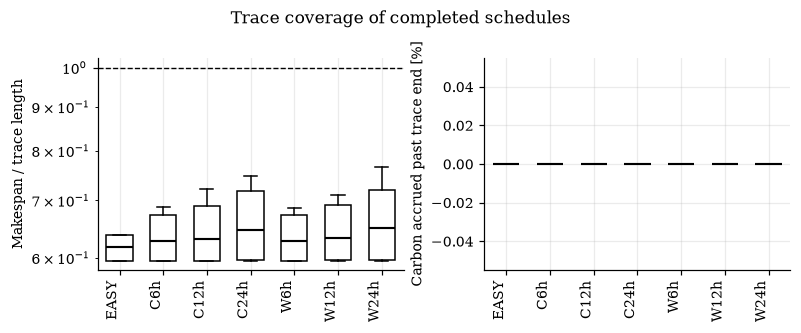

In [7]:
coverage_fig, _ = ca.plot_trace_coverage(coverage)
plt.show()

## Plot: improvement over EASY

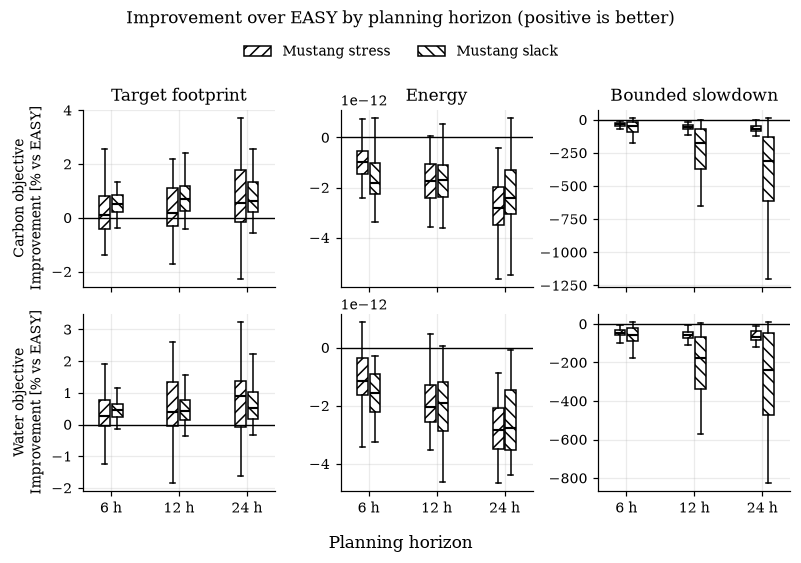

In [8]:
improvement_fig, _ = ca.plot_improvement_vs_easy(paired)
plt.show()

## Plot: scheduling cost

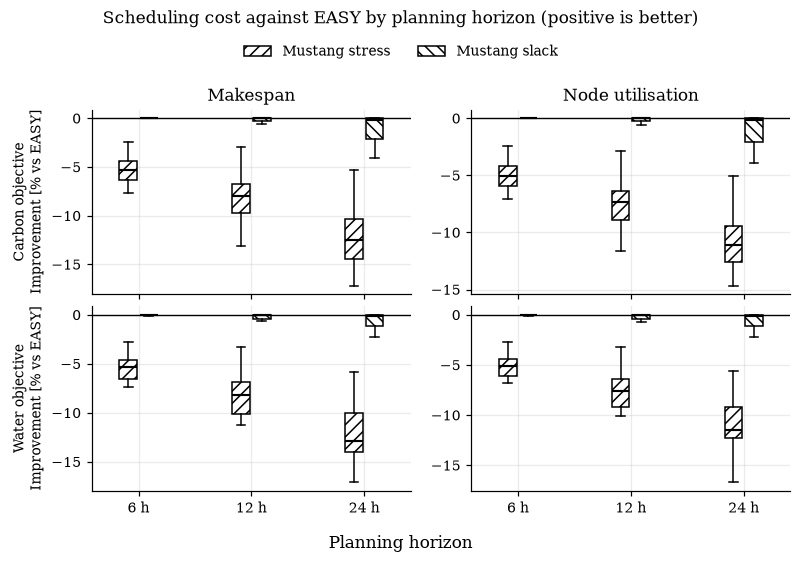

In [9]:
cost_fig, _ = ca.plot_cost_vs_easy(paired)
plt.show()

## Plot: intensity decomposition

Symmetric log axes show positive improvements, negative changes and zero, with a linear interval from -0.1% to +0.1%.


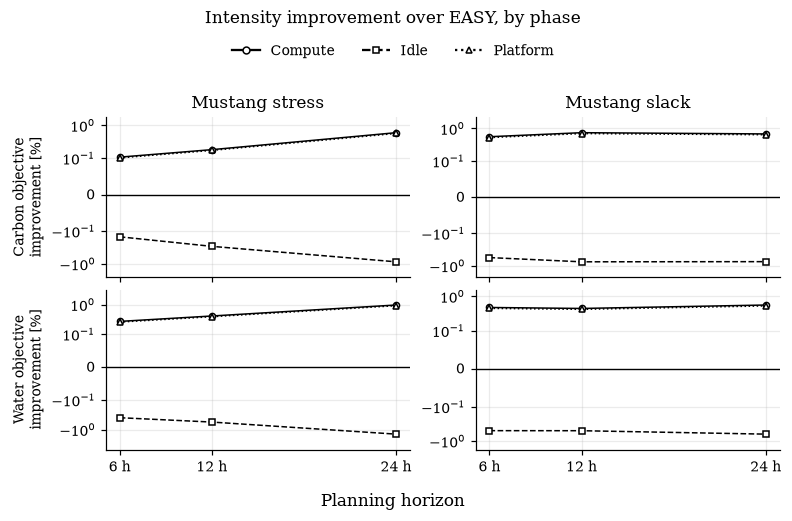

In [10]:
decomposition_fig, _ = ca.plot_intensity_decomposition(paired)
plt.show()

### Compute and idle exposure

Separate rows show compute and idle shares of node-time and energy. Each pair sums to 100% per run; energy shares weight the phases in platform intensity.

C and W denote carbon and water objectives; 6h, 12h and 24h denote planning horizons. EASY appears once per workload. Linear axes fit each panel's full data range, including outliers. Compare tick values across panels because their limits differ.

Node-time sums time across nodes, not elapsed duration or job waiting time. For this always-on campaign, idle node-time is `trace_end * number_of_nodes - time_computing`, over the same horizon as the footprint totals. This includes final idle intervals omitted by the exported counter.


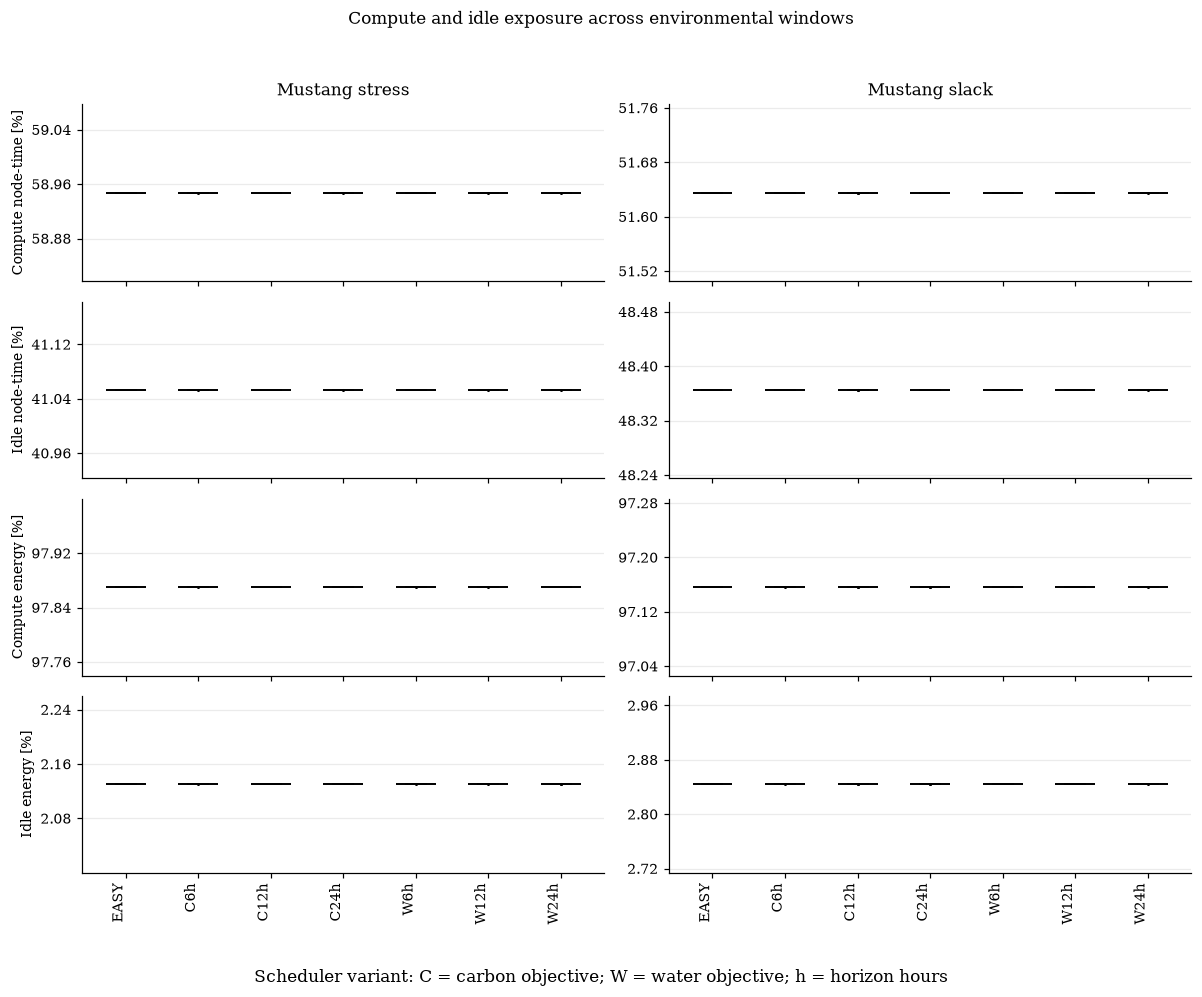

In [11]:
exposure_fig, _ = ca.plot_phase_exposure(run_metrics)
plt.show()

## Plot: footprint versus slowdown

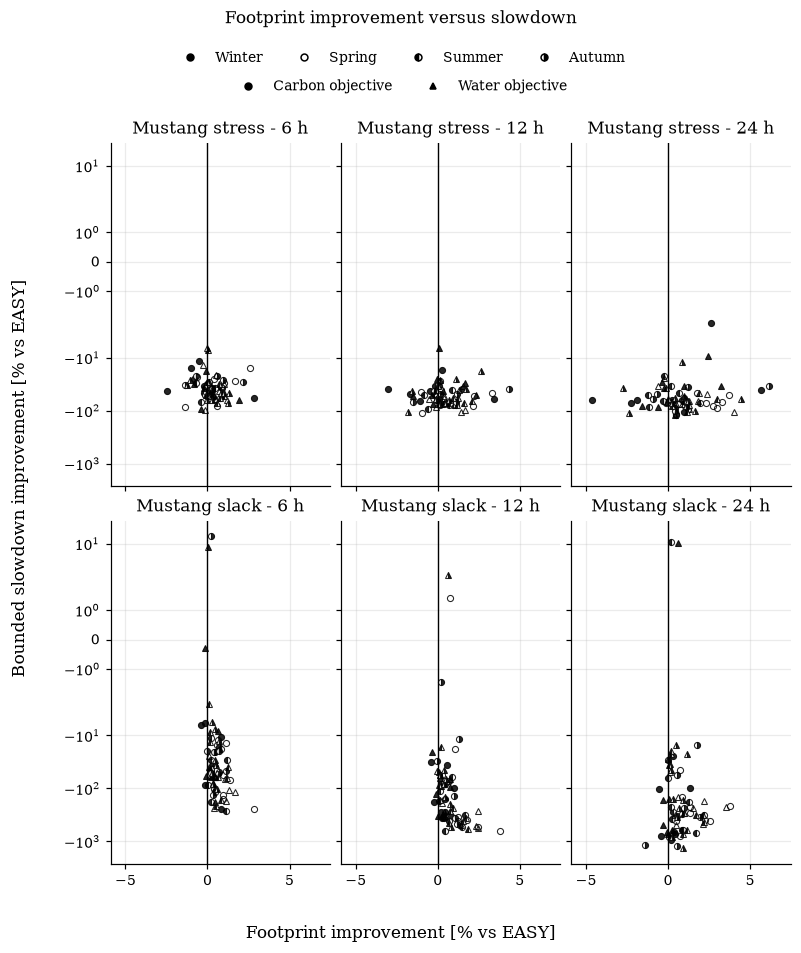

In [12]:
tradeoff_fig, _ = ca.plot_tradeoff_scatter(
    paired,
    "footprint_improvement_pct",
    "Footprint improvement [% vs EASY]",
    "Footprint improvement versus slowdown",
)
plt.show()

## Findings

The campaign uses batsched `ffe1b9f`, 48-day traces and the Mustang workloads, with 432 green runs paired against 72 EASY baselines. Every run is accounted to the end of its trace, so paired runs share one horizon. Unless stated otherwise, values are medians over the 72 windows of each signal and horizon, relative to EASY in the same window, with positive values indicating improvement.

All 504 runs finish within their traces. The maximum makespan is 0.766 of the trace length, so no footprint is charged against a frozen signal.

Footprint improves by 0.36% to 0.60% for carbon and 0.39% to 0.60% for water, and is lower than EASY in 71% to 82% of windows. Compute intensity improves by 0.38% to 0.64%. Idle intensity worsens by 0.46% to 0.79%. Energy is unchanged, since the work and the horizon are the same, so the idle footprint returns only about P_idle/P_compute (3%) of the compute saving.

Each window also carries a multi-week drift: stretching the schedule moves the whole workload into cleaner or dirtier weeks, from -5.3 to +5.8 pp per window, which averages out over windows. The intraday part, the window choice the heuristic makes, is 0.3 to 0.7 pp and lowers the footprint in 431 of the 432 green runs.

The cost is in the schedule. Makespan worsens by 1.6% to 5.4%, waiting time by 6% to 51% and bounded slowdown by 36% to 86%.

From 6h to 24h, the carbon footprint improvement rises from 0.36% to 0.60%, while bounded slowdown worsens from 36% to 86%. Slack windows improve more often (89% to 94% of windows) than stress windows (53% to 72%). Stress concentrates the makespan cost (5% to 13% worse), while slack keeps its makespan and pays in slowdown.

The ceiling comparison has no bound for this campaign, because `shift_ceiling_results.csv.gz` was not regenerated after Trinity was dropped.

## Compute and idle contributions

Both examples compare the carbon objective with a 24-hour planning horizon against EASY, using the German (DE) trace window starting 2019-02-04. The workloads are `mustang_slack` and `mustang_stress`. These are individual experiment pairs, not campaign averages.

The code below selects the four experiment IDs and reproduces the comparisons. Positive changes indicate increases; negative changes indicate decreases.


In [13]:
example_pairs = {
    "mustang_slack": (
        "easy_bf_mustang_slack_DE_2019-02-04",
        "green_window_scheduling_carbon_86400_mustang_slack_DE_2019-02-04",
    ),
    "mustang_stress": (
        "easy_bf_mustang_stress_DE_2019-02-04",
        "green_window_scheduling_carbon_86400_mustang_stress_DE_2019-02-04",
    ),
}
examples = run_metrics.set_index("name")
assert examples.index.is_unique

for workload, (easy_id, green_id) in example_pairs.items():
    easy, green = examples.loc[easy_id], examples.loc[green_id]
    compute_change = 100 * (green.compute_carbon / easy.compute_carbon - 1)
    carbon_change = 100 * (
        green.total_carbon_operational / easy.total_carbon_operational - 1
    )
    idle_intensity_change = 100 * (
        green.idle_carbon_intensity / easy.idle_carbon_intensity - 1
    )
    print(f"{workload}:\n  EASY: {easy_id}\n  Green: {green_id}")
    print(f"  Compute energy: {easy.compute_energy_kwh:,.0f} -> "
          f"{green.compute_energy_kwh:,.0f} kWh; carbon change: {compute_change:+.2f}%")
    print(f"  Idle energy: {easy.idle_energy_kwh:,.0f} -> "
          f"{green.idle_energy_kwh:,.0f} kWh")
    print(f"  Idle carbon intensity: {easy.idle_carbon_intensity:.1f} -> "
          f"{green.idle_carbon_intensity:.1f} gCO2eq/kWh "
          f"({idle_intensity_change:+.0f}%)")
    print(f"  Operational carbon change: {carbon_change:+.2f}%\n")


mustang_slack:
  EASY: easy_bf_mustang_slack_DE_2019-02-04
  Green: green_window_scheduling_carbon_86400_mustang_slack_DE_2019-02-04
  Compute energy: 304,490 -> 304,490 kWh; carbon change: -0.89%
  Idle energy: 8,913 -> 8,913 kWh
  Idle carbon intensity: 261.4 -> 264.8 gCO2eq/kWh (+1%)
  Operational carbon change: -0.84%

mustang_stress:
  EASY: easy_bf_mustang_stress_DE_2019-02-04
  Green: green_window_scheduling_carbon_86400_mustang_stress_DE_2019-02-04
  Compute energy: 347,609 -> 347,609 kWh; carbon change: -5.91%
  Idle energy: 7,565 -> 7,565 kWh
  Idle carbon intensity: 258.7 -> 287.8 gCO2eq/kWh (+11%)
  Operational carbon change: -5.64%



On mustang slack, compute carbon falls by 0.89% and total carbon by 0.84%. Compute and idle energy are unchanged, at 304,490 and 8,913 kWh. Idle intensity rises by 1%, from 261.4 to 264.8 gCO2eq/kWh.

On mustang stress, compute carbon falls by 5.91% and total carbon by 5.64%. Idle energy is unchanged at 7,565 kWh. Idle intensity rises by 11%, from 258.7 to 287.8 gCO2eq/kWh, which adds 0.22 t against 7.06 t less compute carbon.

With always-on nodes and a common horizon, each node-hour of compute moved out of a dirty period leaves a node-hour of idle in it. Idle therefore returns P_idle/P_compute of the compute saving, and the change in total carbon follows the change in compute carbon.

This window is not representative of the heuristic. Splitting the trace into weekly, daily and intraday components, the stress change of -5.64% is -4.18 pp weekly, -0.98 pp daily and -0.47 pp intraday. The heuristic only sees the intraday part, since its horizon is at most 24 h. DE 2019-02-04 is the second window most favoured by the weekly drift in the campaign.